In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from datetime import datetime

# Scikit-learn
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error,
    confusion_matrix, classification_report, accuracy_score
)

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Google Colab file upload
try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\U0001f5a5\ufe0f  Device : {DEVICE}")
print(f"\U0001f522  PyTorch : {torch.__version__}")

🖥️  Device : cuda
🔢  PyTorch : 2.11.0+cu130


In [2]:
if IN_COLAB:
    print("\U0001f4c1 Upload GSPC.csv (S&P 500 daily data from Yahoo Finance)")
    uploaded = colab_files.upload()
    csv_path = list(uploaded.keys())[0]
else:
    csv_path = "GSPC.csv"  # local fallback

df = pd.read_csv(csv_path, parse_dates=["Date"])
df.sort_values("Date", inplace=True)
df.reset_index(drop=True, inplace=True)

print(f"\n\U0001f4ca Dataset shape : {df.shape}")
print(f"\U0001f4c5 Date range    : {df['Date'].min().date()} \u2192 {df['Date'].max().date()}")
print(f"\u274c Missing values: {df.isnull().sum().sum()}")
print(f"\U0001f501 Duplicates    : {df.duplicated().sum()}")
df.head()

📁 Upload GSPC.csv (S&P 500 daily data from Yahoo Finance)


Saving GSPC.csv to GSPC.csv

📊 Dataset shape : (24801, 7)
📅 Date range    : 1927-12-30 → 2026-09-25
❌ Missing values: 0
🔁 Duplicates    : 0


,Date,Open,High,Low,Close,Adj Close,Volume
0,1927-12-30,17.660000,17.660000,17.660000,17.660000,17.660000,0
1,1928-01-03,17.760000,17.760000,17.760000,17.760000,17.760000,0
2,1928-01-04,17.719999,17.719999,17.719999,17.719999,17.719999,0
3,1928-01-05,17.549999,17.549999,17.549999,17.549999,17.549999,0
4,1928-01-06,17.660000,17.660000,17.660000,17.660000,17.660000,0


In [3]:
# Validate OHLC consistency
invalid_ohlc = df[(df["High"] < df["Low"]) |
                  (df["Close"] > df["High"]) |
                  (df["Close"] < df["Low"])].shape[0]
print(f"\u26a0\ufe0f  Invalid OHLC rows: {invalid_ohlc}")

# Check zero-volume rows (expected for pre-1950s data)
zero_vol = (df["Volume"] == 0).sum()
print(f"\U0001f4c9 Zero-volume rows : {zero_vol} (pre-1950s historical data)")

⚠️  Invalid OHLC rows: 0
📉 Zero-volume rows : 5497 (pre-1950s historical data)


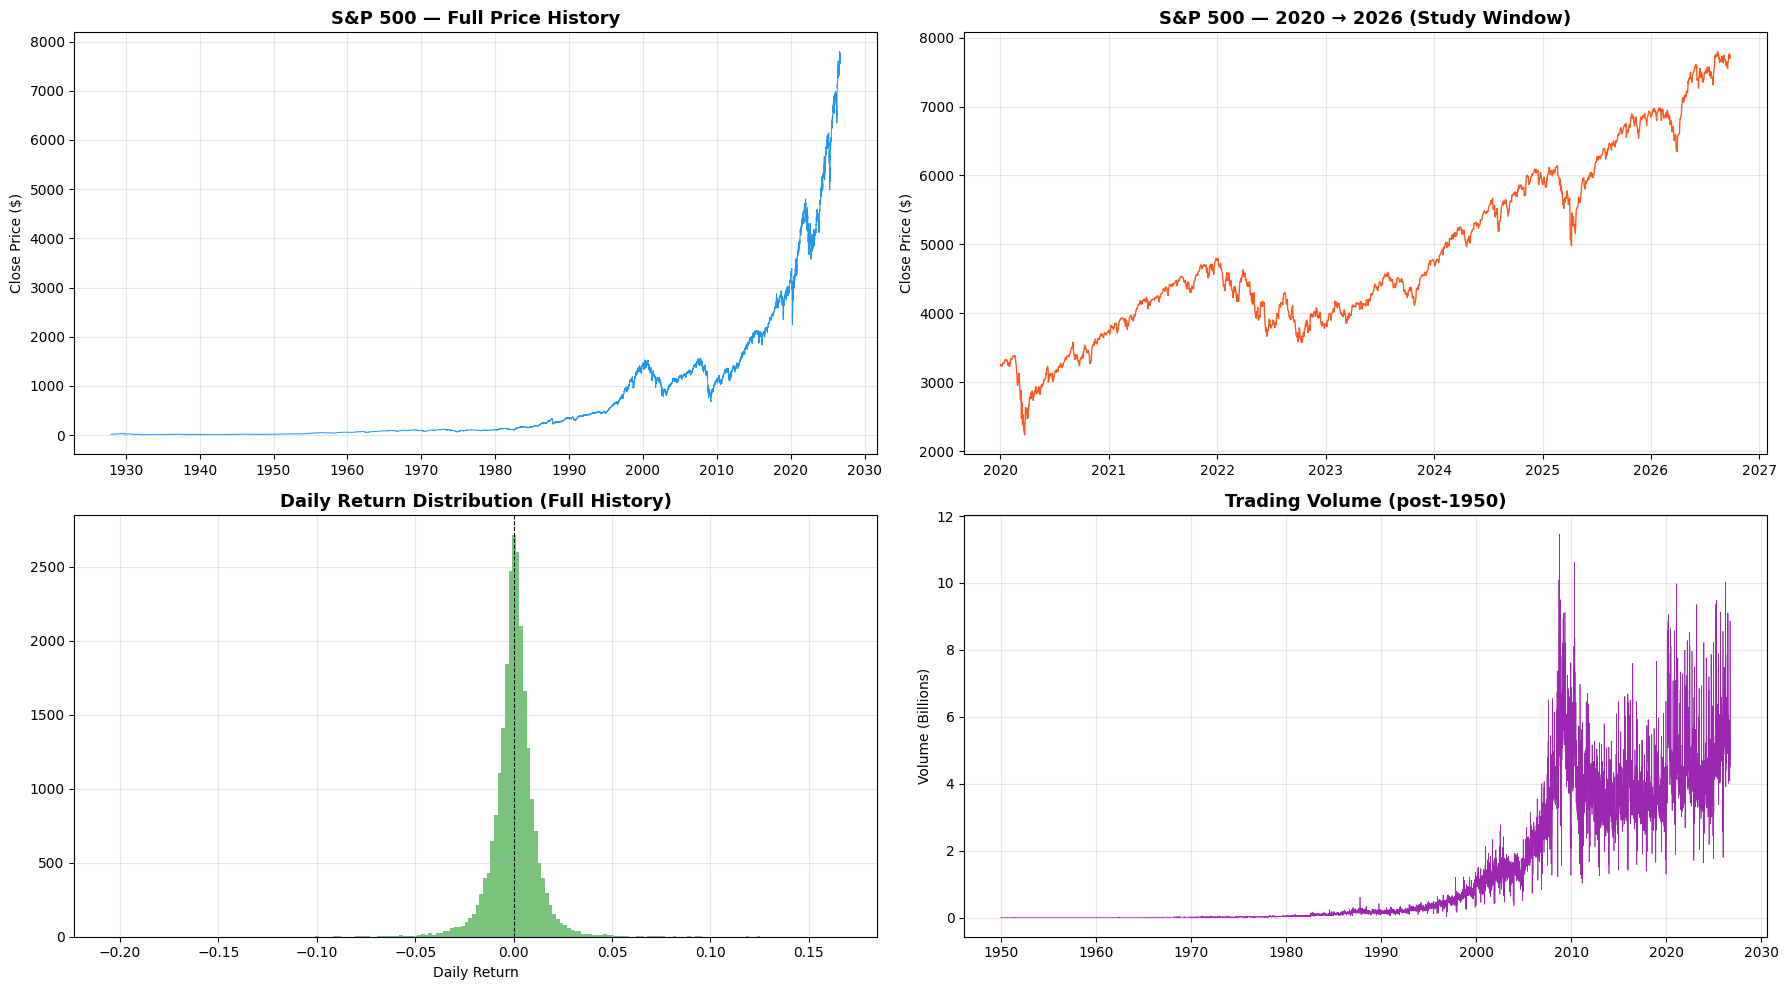

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(18, 10))

# Full price history
axes[0, 0].plot(df["Date"], df["Close"], linewidth=0.7, color="#2196F3")
axes[0, 0].set_title("S&P 500 \u2014 Full Price History", fontsize=13, fontweight="bold")
axes[0, 0].set_ylabel("Close Price ($)")
axes[0, 0].xaxis.set_major_locator(mdates.YearLocator(10))
axes[0, 0].grid(alpha=0.3)

# Price 2020-2026 (our training window)
mask = df["Date"] >= "2020-01-01"
axes[0, 1].plot(df.loc[mask, "Date"], df.loc[mask, "Close"], linewidth=1, color="#FF5722")
axes[0, 1].set_title("S&P 500 \u2014 2020 \u2192 2026 (Study Window)", fontsize=13, fontweight="bold")
axes[0, 1].set_ylabel("Close Price ($)")
axes[0, 1].grid(alpha=0.3)

# Daily returns distribution
daily_ret = df["Close"].pct_change().dropna()
axes[1, 0].hist(daily_ret, bins=200, color="#4CAF50", alpha=0.75, edgecolor="none")
axes[1, 0].set_title("Daily Return Distribution (Full History)", fontsize=13, fontweight="bold")
axes[1, 0].set_xlabel("Daily Return")
axes[1, 0].axvline(0, color="black", linestyle="--", linewidth=0.8)
axes[1, 0].grid(alpha=0.3)

# Volume (post-1950)
vol_mask = df["Volume"] > 0
axes[1, 1].plot(df.loc[vol_mask, "Date"], df.loc[vol_mask, "Volume"] / 1e9, linewidth=0.5, color="#9C27B0")
axes[1, 1].set_title("Trading Volume (post-1950)", fontsize=13, fontweight="bold")
axes[1, 1].set_ylabel("Volume (Billions)")
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
df["Daily_Return"]     = df["Close"].pct_change()
df["Price_Range_Pct"]  = (df["High"] - df["Low"]) / df["Close"]
df["Open_Close_Pct"]   = (df["Close"] - df["Open"]) / df["Open"]

df["MA_7"]  = df["Close"].rolling(7).mean()
df["MA_20"] = df["Close"].rolling(20).mean()

df["Close_MA7_Ratio"]  = df["Close"] / df["MA_7"] - 1
df["Close_MA20_Ratio"] = df["Close"] / df["MA_20"] - 1

df["Volatility_20"]    = df["Daily_Return"].rolling(20).std()
df["MA7_MA20_Cross"]   = df["MA_7"] / df["MA_20"] - 1

df["Momentum_5"]       = df["Close"] / df["Close"].shift(5) - 1
df["Momentum_10"]      = df["Close"] / df["Close"].shift(10) - 1

# Target: next-day return
df["Target_Return"] = df["Close"].shift(-1) / df["Close"] - 1

# Drop helper columns & NaN rows
df.drop(columns=["MA_7", "MA_20"], inplace=True)
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

FEATURE_COLS = [
    "Daily_Return", "Price_Range_Pct", "Open_Close_Pct",
    "Close_MA7_Ratio", "Close_MA20_Ratio", "Volatility_20",
    "MA7_MA20_Cross", "Momentum_5", "Momentum_10"
]

print(f"\u2705 Features engineered: {len(FEATURE_COLS)}")
print(f"\U0001f4ca Dataset after feature eng: {df.shape}")

✅ Features engineered: 9
📊 Dataset after feature eng: (24780, 17)


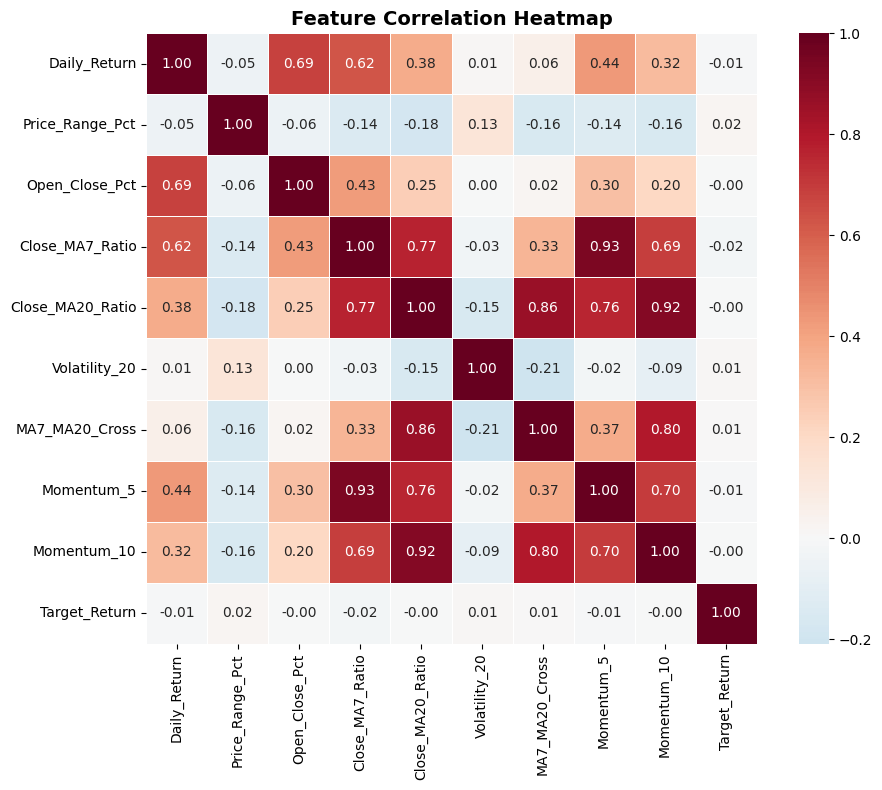

In [6]:
fig, ax = plt.subplots(figsize=(10, 8))
corr = df[FEATURE_COLS + ["Target_Return"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, square=True, ax=ax, linewidths=0.5)
ax.set_title("Feature Correlation Heatmap", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [7]:
THRESHOLD = 0.005  # +/-0.5% threshold

def classify_trend(ret, threshold=THRESHOLD):
    if ret > threshold:
        return "BULLISH"
    elif ret < -threshold:
        return "BEARISH"
    else:
        return "NEUTRAL"

df["Trend"] = df["Target_Return"].apply(classify_trend)

print("\n\U0001f4c8 Trend distribution (full dataset):")
print(df["Trend"].value_counts())
print(f"\nThreshold used: \u00b1{THRESHOLD*100:.1f}%")


📈 Trend distribution (full dataset):
Trend
NEUTRAL    12345
BULLISH     6628
BEARISH     5807
Name: count, dtype: int64

Threshold used: ±0.5%


In [17]:
TRAIN_START = "1927-01-01"
TRAIN_END   = "2022-12-31"
VALID_START = "2023-01-01"
VALID_END   = "2024-12-31"
TEST_START  = "2025-01-01"
TEST_END    = "2026-12-31"

train_df = df[(df["Date"] >= TRAIN_START) & (df["Date"] <= TRAIN_END)].copy()
valid_df = df[(df["Date"] >= VALID_START) & (df["Date"] <= VALID_END)].copy()
test_df  = df[(df["Date"] >= TEST_START)  & (df["Date"] <= TEST_END)].copy()

print(f"\U0001f7e2 Train : {train_df.shape[0]:>5} rows  ({train_df['Date'].min().date()} \u2192 {train_df['Date'].max().date()})")
print(f"\U0001f7e1 Valid : {valid_df.shape[0]:>5} rows  ({valid_df['Date'].min().date()} \u2192 {valid_df['Date'].max().date()})")
print(f"\U0001f534 Test  : {test_df.shape[0]:>5} rows  ({test_df['Date'].min().date()} \u2192 {test_df['Date'].max().date()})")

🟢 Train : 23845 rows  (1928-01-30 → 2022-12-30)
🟡 Valid :   502 rows  (2023-01-03 → 2024-12-31)
🔴 Test  :   433 rows  (2025-01-02 → 2026-09-24)


In [18]:
feature_scaler = StandardScaler()
target_scaler  = StandardScaler()

# Fit on training data ONLY
feature_scaler.fit(train_df[FEATURE_COLS].values)
target_scaler.fit(train_df[["Target_Return"]].values)

# Transform all splits
for split in [train_df, valid_df, test_df]:
    split[FEATURE_COLS] = feature_scaler.transform(split[FEATURE_COLS].values)
    split["Target_Return_Scaled"] = target_scaler.transform(
        split[["Target_Return"]].values
    )

print("\u2705 Scalers fit on training data only \u2014 applied to all splits")

✅ Scalers fit on training data only — applied to all splits


In [19]:
LOOKBACK = 60

# Concatenate all splits for contiguous sequence creation
all_data = pd.concat([train_df, valid_df, test_df], ignore_index=True)

# Index boundaries
train_end_idx = len(train_df)
valid_end_idx = train_end_idx + len(valid_df)
test_end_idx  = valid_end_idx + len(test_df)

all_features = all_data[FEATURE_COLS].values
all_targets  = all_data["Target_Return_Scaled"].values
all_closes   = all_data["Close"].values
all_dates    = all_data["Date"].values
all_returns  = all_data["Target_Return"].values
all_trends   = all_data["Trend"].values


def create_sequences(features, targets, start_idx, end_idx, lookback=LOOKBACK):
    """Create (X, y) sequences where each X is a lookback-length window."""
    X, y, indices = [], [], []
    for i in range(max(start_idx, lookback), end_idx):
        X.append(features[i - lookback : i])
        y.append(targets[i])
        indices.append(i)
    return np.array(X), np.array(y), np.array(indices)


X_train, y_train, idx_train = create_sequences(all_features, all_targets, 0, train_end_idx)
X_valid, y_valid, idx_valid = create_sequences(all_features, all_targets, train_end_idx, valid_end_idx)
X_test,  y_test,  idx_test  = create_sequences(all_features, all_targets, valid_end_idx, test_end_idx)

print(f"\U0001f4e6 Sequences created (lookback = {LOOKBACK}):")
print(f"   Train : X={X_train.shape}, y={y_train.shape}")
print(f"   Valid : X={X_valid.shape}, y={y_valid.shape}")
print(f"   Test  : X={X_test.shape},  y={y_test.shape}")

📦 Sequences created (lookback = 60):
   Train : X=(23785, 60, 9), y=(23785,)
   Valid : X=(502, 60, 9), y=(502,)
   Test  : X=(433, 60, 9),  y=(433,)


In [20]:
class StockDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


BATCH_SIZE = 64

train_dataset = StockDataset(X_train, y_train)
valid_dataset = StockDataset(X_valid, y_valid)
test_dataset  = StockDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

print(f"\u2705 DataLoaders ready  (batch_size={BATCH_SIZE})")

✅ DataLoaders ready  (batch_size=64)


In [21]:
def evaluate_predictions(actual_returns, predicted_returns,
                         actual_closes, actual_trends,
                         threshold=THRESHOLD, label="Model"):
    """
    Compute all evaluation metrics from predicted vs actual RETURNS.
    Predicted prices are recovered as:  price = close[t] * (1 + predicted_return)
    """
    actual_returns    = np.array(actual_returns)
    predicted_returns = np.array(predicted_returns)
    actual_closes     = np.array(actual_closes)
    actual_trends     = np.array(actual_trends)

    # Recover prices
    actual_prices    = actual_closes * (1 + actual_returns)
    predicted_prices = actual_closes * (1 + predicted_returns)

    # Regression metrics (on prices)
    rmse = np.sqrt(mean_squared_error(actual_prices, predicted_prices))
    mae  = mean_absolute_error(actual_prices, predicted_prices)

    # Directional accuracy (on returns)
    actual_dir    = (actual_returns > 0).astype(int)
    predicted_dir = (predicted_returns > 0).astype(int)
    dir_acc = accuracy_score(actual_dir, predicted_dir) * 100

    # Trend labels from predicted returns
    predicted_trends = np.array([classify_trend(r, threshold) for r in predicted_returns])
    trend_acc = accuracy_score(actual_trends, predicted_trends) * 100

    cm = confusion_matrix(actual_trends, predicted_trends,
                          labels=["BULLISH", "NEUTRAL", "BEARISH"])

    report = classification_report(actual_trends, predicted_trends,
                                   labels=["BULLISH", "NEUTRAL", "BEARISH"],
                                   output_dict=True, zero_division=0)

    return {
        "label": label,
        "rmse": rmse,
        "mae": mae,
        "dir_acc": dir_acc,
        "trend_acc": trend_acc,
        "confusion_matrix": cm,
        "classification_report": report,
        "actual_prices": actual_prices,
        "predicted_prices": predicted_prices,
        "predicted_trends": predicted_trends,
    }


# --- Naive baseline: predicted return = 0  (tomorrow = today) ---
naive_pred_returns_test   = np.zeros(len(idx_test))
naive_actual_returns_test = all_returns[idx_test]
naive_closes_test         = all_closes[idx_test]
naive_trends_test         = all_trends[idx_test]

naive_metrics = evaluate_predictions(
    naive_actual_returns_test, naive_pred_returns_test,
    naive_closes_test, naive_trends_test, label="Naive Baseline"
)

print("=" * 55)
print("  \U0001f4cc  NAIVE PERSISTENCE BASELINE  (Test Set)")
print("=" * 55)
print(f"  RMSE                : {naive_metrics['rmse']:.2f}")
print(f"  MAE                 : {naive_metrics['mae']:.2f}")
print(f"  Directional Accuracy: {naive_metrics['dir_acc']:.2f}%")
print(f"  Trend Accuracy      : {naive_metrics['trend_acc']:.2f}%")
print("=" * 55)

  📌  NAIVE PERSISTENCE BASELINE  (Test Set)
  RMSE                : 63.78
  MAE                 : 44.82
  Directional Accuracy: 44.57%
  Trend Accuracy      : 48.73%


In [22]:
# Flatten lookback window -> single feature vector per sample
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_valid_flat = X_valid.reshape(X_valid.shape[0], -1)
X_test_flat  = X_test.reshape(X_test.shape[0], -1)

lin_model = LinearRegression()
lin_model.fit(X_train_flat, y_train)

# Predict (scaled) -> inverse-transform -> returns
lin_pred_scaled_valid = lin_model.predict(X_valid_flat).reshape(-1, 1)
lin_pred_scaled_test  = lin_model.predict(X_test_flat).reshape(-1, 1)

lin_pred_returns_valid = target_scaler.inverse_transform(lin_pred_scaled_valid).flatten()
lin_pred_returns_test  = target_scaler.inverse_transform(lin_pred_scaled_test).flatten()

# Evaluate on test set
lin_metrics = evaluate_predictions(
    all_returns[idx_test], lin_pred_returns_test,
    all_closes[idx_test], all_trends[idx_test], label="Linear Regression"
)

print("=" * 55)
print("  \U0001f4cc  LINEAR REGRESSION BASELINE  (Test Set)")
print("=" * 55)
print(f"  RMSE                : {lin_metrics['rmse']:.2f}")
print(f"  MAE                 : {lin_metrics['mae']:.2f}")
print(f"  Directional Accuracy: {lin_metrics['dir_acc']:.2f}%")
print(f"  Trend Accuracy      : {lin_metrics['trend_acc']:.2f}%")
print("=" * 55)

  📌  LINEAR REGRESSION BASELINE  (Test Set)
  RMSE                : 65.09
  MAE                 : 46.43
  Directional Accuracy: 52.89%
  Trend Accuracy      : 47.58%


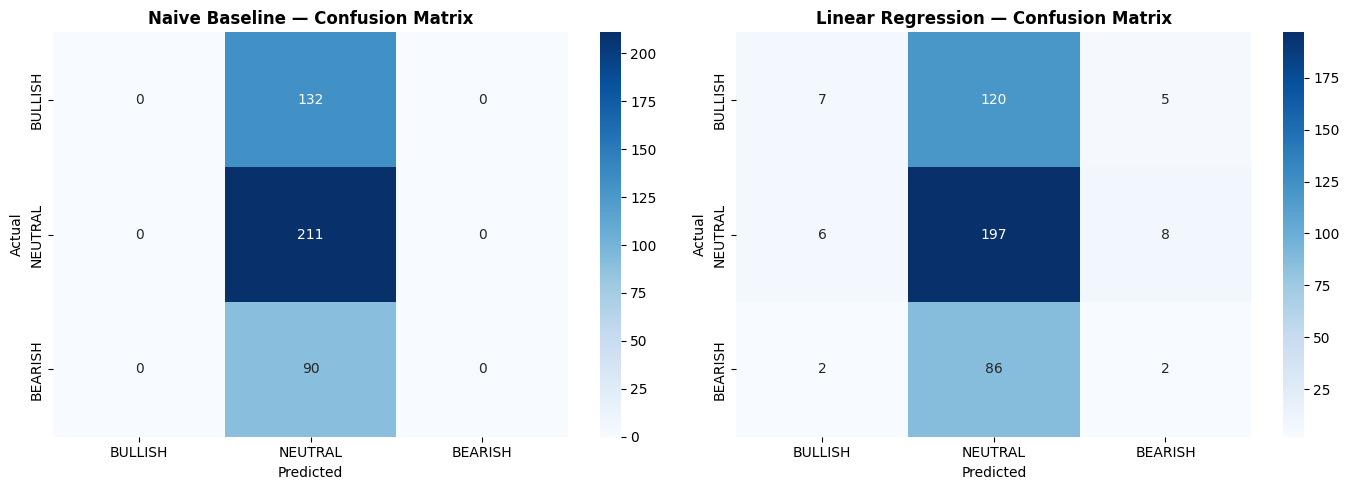

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
labels = ["BULLISH", "NEUTRAL", "BEARISH"]

for ax, metrics in zip(axes, [naive_metrics, lin_metrics]):
    sns.heatmap(metrics["confusion_matrix"], annot=True, fmt="d",
                cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(f"{metrics['label']} \u2014 Confusion Matrix", fontweight="bold")
    ax.set_ylabel("Actual")
    ax.set_xlabel("Predicted")

plt.tight_layout()
plt.show()

In [24]:
class LSTMPredictor(nn.Module):
    """Stacked LSTM for next-day return prediction."""
    def __init__(self, input_size, hidden_size=128, num_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        last_hidden = lstm_out[:, -1, :]
        return self.fc(last_hidden)


INPUT_SIZE  = len(FEATURE_COLS)
HIDDEN_SIZE = 128
NUM_LAYERS  = 2
DROPOUT     = 0.2

model = LSTMPredictor(INPUT_SIZE, HIDDEN_SIZE, NUM_LAYERS, DROPOUT).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
print(f"\n\U0001f9e0 LSTM Model Summary")
print(f"   Input size  : {INPUT_SIZE}")
print(f"   Hidden size : {HIDDEN_SIZE}")
print(f"   LSTM layers : {NUM_LAYERS}")
print(f"   Dropout     : {DROPOUT}")
print(f"   Total params: {total_params:,}")
print(model)


🧠 LSTM Model Summary
   Input size  : 9
   Hidden size : 128
   LSTM layers : 2
   Dropout     : 0.2
   Total params: 203,393
LSTMPredictor(
  (lstm): LSTM(9, 128, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [27]:
EPOCHS        = 200
LEARNING_RATE = 0.001
PATIENCE      = 15
CLIP_NORM     = 1.0

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=5
)

best_val_loss = float("inf")
patience_counter = 0
train_losses = []
valid_losses = []

print("\n\U0001f680 Training LSTM ...\n")

for epoch in range(1, EPOCHS + 1):
    # ---- Train ----
    model.train()
    epoch_train_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
        optimizer.zero_grad()
        preds = model(X_batch)
        loss = criterion(preds, y_batch)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM)
        optimizer.step()
        epoch_train_loss += loss.item() * X_batch.size(0)
    epoch_train_loss /= len(train_dataset)

    # ---- Validate ----
    model.eval()
    epoch_val_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in valid_loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            preds = model(X_batch)
            loss = criterion(preds, y_batch)
            epoch_val_loss += loss.item() * X_batch.size(0)
    epoch_val_loss /= len(valid_dataset)

    train_losses.append(epoch_train_loss)
    valid_losses.append(epoch_val_loss)

    scheduler.step(epoch_val_loss)

    # Early stopping
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        patience_counter = 0
        best_model_state = model.state_dict().copy()
        best_epoch = epoch
    else:
        patience_counter += 1

    if epoch % 10 == 0 or epoch == 1 or patience_counter == PATIENCE:
        print(f"  Epoch {epoch:>3}/{EPOCHS}  |  "
              f"Train Loss: {epoch_train_loss:.6f}  |  "
              f"Val Loss: {epoch_val_loss:.6f}  |  "
              f"Patience: {patience_counter}/{PATIENCE}")

    if patience_counter >= PATIENCE:
        print(f"\n\u23f9\ufe0f  Early stopping at epoch {epoch}  (best epoch: {best_epoch})")
        break

# Load best model
model.load_state_dict(best_model_state)
print(f"\n\u2705 Best model restored from epoch {best_epoch}  (val_loss={best_val_loss:.6f})")


🚀 Training LSTM ...

  Epoch   1/200  |  Train Loss: 1.004135  |  Val Loss: 0.456402  |  Patience: 0/15
  Epoch  10/200  |  Train Loss: 0.986408  |  Val Loss: 0.458151  |  Patience: 8/15
  Epoch  17/200  |  Train Loss: 0.932335  |  Val Loss: 0.458169  |  Patience: 15/15

⏹️  Early stopping at epoch 17  (best epoch: 2)

✅ Best model restored from epoch 2  (val_loss=0.455536)


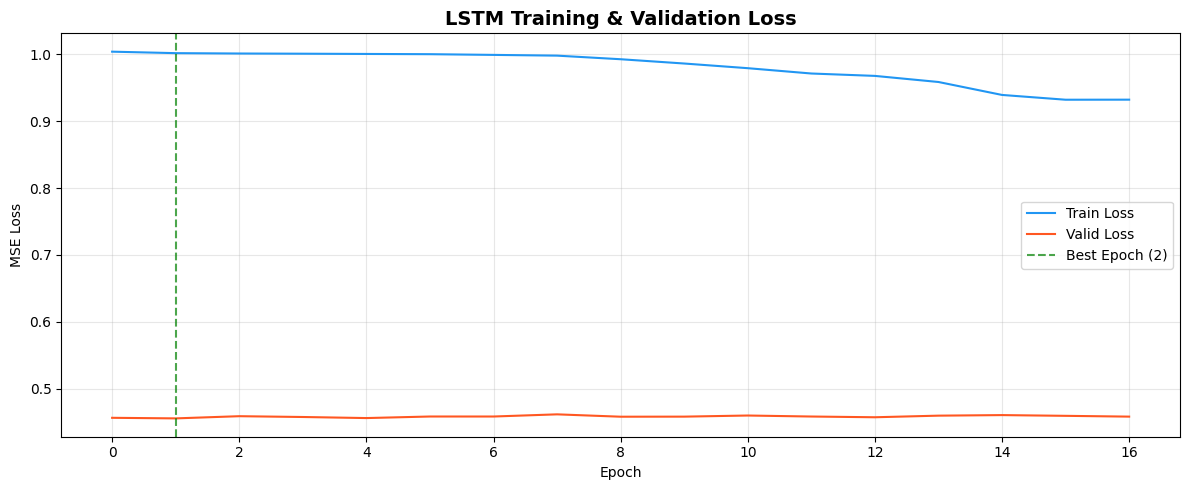

In [28]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train_losses, label="Train Loss", linewidth=1.5, color="#2196F3")
ax.plot(valid_losses, label="Valid Loss", linewidth=1.5, color="#FF5722")
ax.axvline(best_epoch - 1, color="green", linestyle="--", alpha=0.7,
           label=f"Best Epoch ({best_epoch})")
ax.set_title("LSTM Training & Validation Loss", fontsize=14, fontweight="bold")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE Loss")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
model.eval()
lstm_pred_scaled = []
with torch.no_grad():
    for X_batch, _ in test_loader:
        X_batch = X_batch.to(DEVICE)
        preds = model(X_batch)
        lstm_pred_scaled.append(preds.cpu().numpy())

lstm_pred_scaled = np.concatenate(lstm_pred_scaled, axis=0)
lstm_pred_returns = target_scaler.inverse_transform(lstm_pred_scaled).flatten()

lstm_metrics = evaluate_predictions(
    all_returns[idx_test], lstm_pred_returns,
    all_closes[idx_test], all_trends[idx_test], label="LSTM"
)

print("=" * 55)
print("  \U0001f9e0  LSTM MODEL  (Test Set)")
print("=" * 55)
print(f"  RMSE                : {lstm_metrics['rmse']:.2f}")
print(f"  MAE                 : {lstm_metrics['mae']:.2f}")
print(f"  Directional Accuracy: {lstm_metrics['dir_acc']:.2f}%")
print(f"  Trend Accuracy      : {lstm_metrics['trend_acc']:.2f}%")
print("=" * 55)

  🧠  LSTM MODEL  (Test Set)
  RMSE                : 64.61
  MAE                 : 44.61
  Directional Accuracy: 52.66%
  Trend Accuracy      : 49.88%


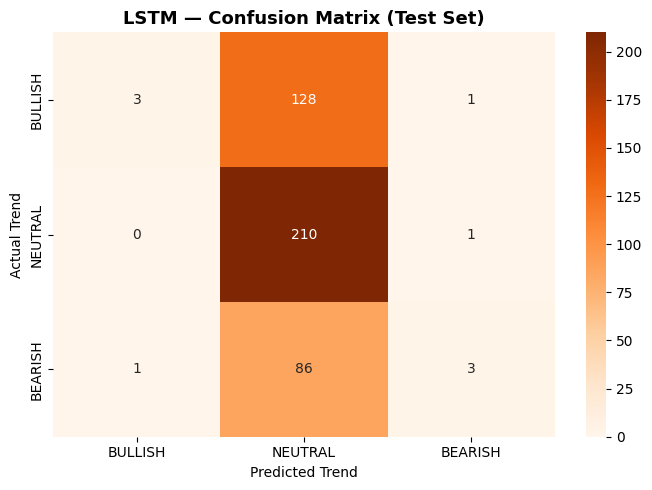


📋 LSTM Classification Report (Test Set):

              precision    recall  f1-score   support

     BULLISH       0.75      0.02      0.04       132
     NEUTRAL       0.50      1.00      0.66       211
     BEARISH       0.60      0.03      0.06        90

    accuracy                           0.50       433
   macro avg       0.62      0.35      0.26       433
weighted avg       0.59      0.50      0.35       433



In [30]:
fig, ax = plt.subplots(figsize=(7, 5))
labels = ["BULLISH", "NEUTRAL", "BEARISH"]
sns.heatmap(lstm_metrics["confusion_matrix"], annot=True, fmt="d",
            cmap="Oranges", xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_title("LSTM \u2014 Confusion Matrix (Test Set)", fontsize=13, fontweight="bold")
ax.set_ylabel("Actual Trend")
ax.set_xlabel("Predicted Trend")
plt.tight_layout()
plt.show()

# Classification report
print("\n\U0001f4cb LSTM Classification Report (Test Set):\n")
lstm_trend_preds = lstm_metrics["predicted_trends"]
print(classification_report(
    all_trends[idx_test], lstm_trend_preds,
    labels=["BULLISH", "NEUTRAL", "BEARISH"], zero_division=0
))


  📊  BASELINE COMPARISON  (Test Set: 2025 → 2026)
            Model  RMSE ($)  MAE ($)  Dir. Accuracy (%)  Trend Accuracy (%)
   Naive Baseline     63.78    44.82              44.57               48.73
Linear Regression     65.09    46.43              52.89               47.58
             LSTM     64.61    44.61              52.66               49.88


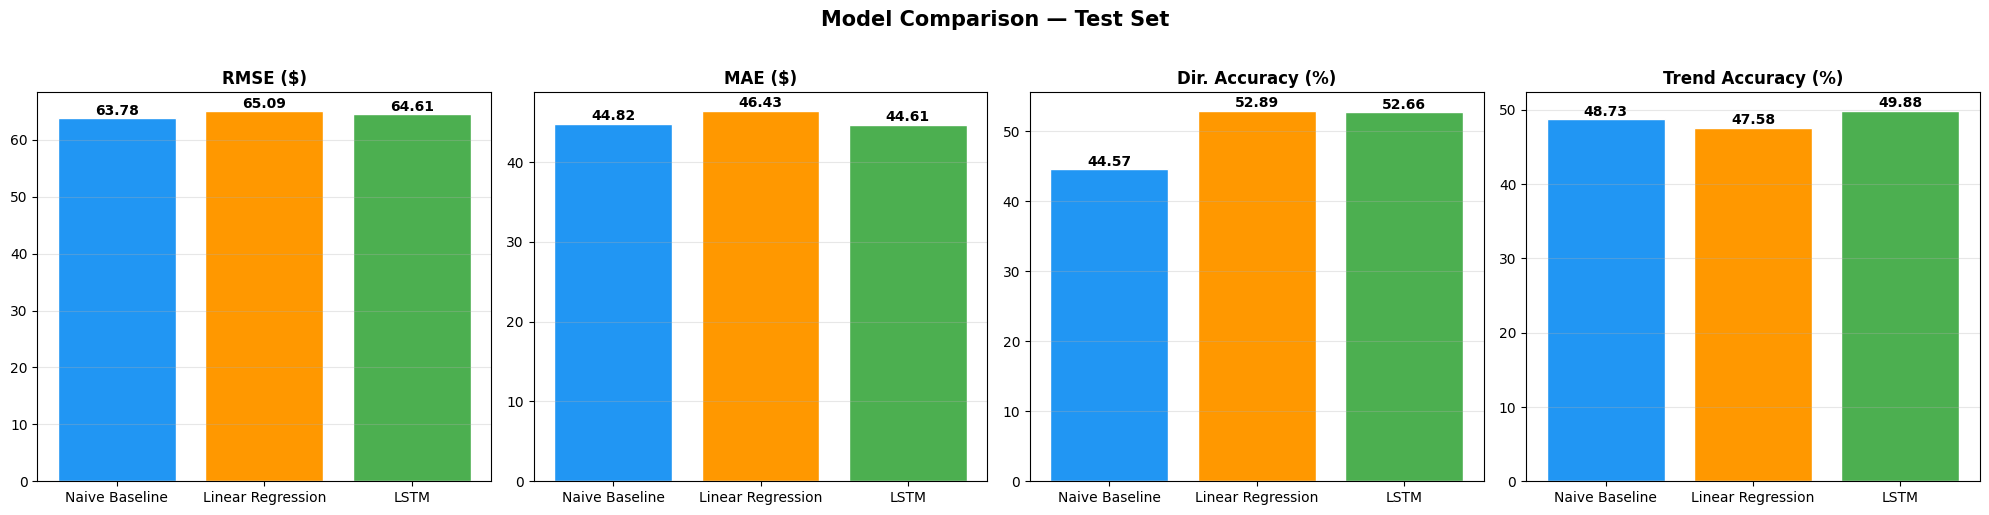

In [31]:
comparison_data = []
for m in [naive_metrics, lin_metrics, lstm_metrics]:
    comparison_data.append({
        "Model": m["label"],
        "RMSE ($)": round(m["rmse"], 2),
        "MAE ($)": round(m["mae"], 2),
        "Dir. Accuracy (%)": round(m["dir_acc"], 2),
        "Trend Accuracy (%)": round(m["trend_acc"], 2),
    })

comparison_df = pd.DataFrame(comparison_data)
print("\n" + "=" * 70)
print("  \U0001f4ca  BASELINE COMPARISON  (Test Set: 2025 \u2192 2026)")
print("=" * 70)
print(comparison_df.to_string(index=False))
print("=" * 70)

# Bar chart
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
metrics_to_plot = ["RMSE ($)", "MAE ($)", "Dir. Accuracy (%)", "Trend Accuracy (%)"]
colors = ["#2196F3", "#FF9800", "#4CAF50"]

for ax, metric in zip(axes, metrics_to_plot):
    vals = comparison_df[metric].values
    bars = ax.bar(comparison_df["Model"], vals, color=colors, edgecolor="white")
    ax.set_title(metric, fontsize=12, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                f"{v}", ha="center", fontsize=10, fontweight="bold")

plt.suptitle("Model Comparison \u2014 Test Set", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

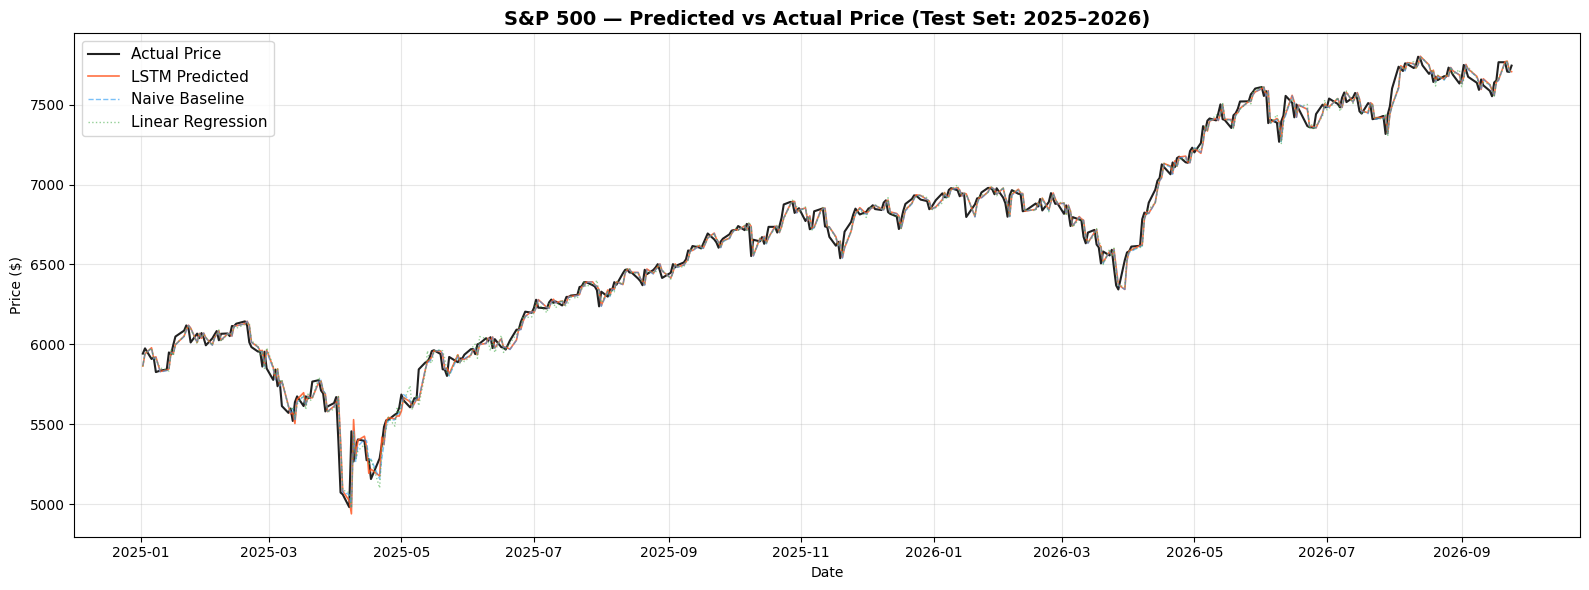

In [32]:
test_dates = all_dates[idx_test]

fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(test_dates, lstm_metrics["actual_prices"],
        label="Actual Price", linewidth=1.5, color="#212121")
ax.plot(test_dates, lstm_metrics["predicted_prices"],
        label="LSTM Predicted", linewidth=1.2, color="#FF5722", alpha=0.85)
ax.plot(test_dates, naive_metrics["predicted_prices"],
        label="Naive Baseline", linewidth=1, color="#2196F3", alpha=0.6, linestyle="--")
ax.plot(test_dates, lin_metrics["predicted_prices"],
        label="Linear Regression", linewidth=1, color="#4CAF50", alpha=0.6, linestyle=":")

ax.set_title("S&P 500 \u2014 Predicted vs Actual Price (Test Set: 2025\u20132026)",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Date")
ax.set_ylabel("Price ($)")
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

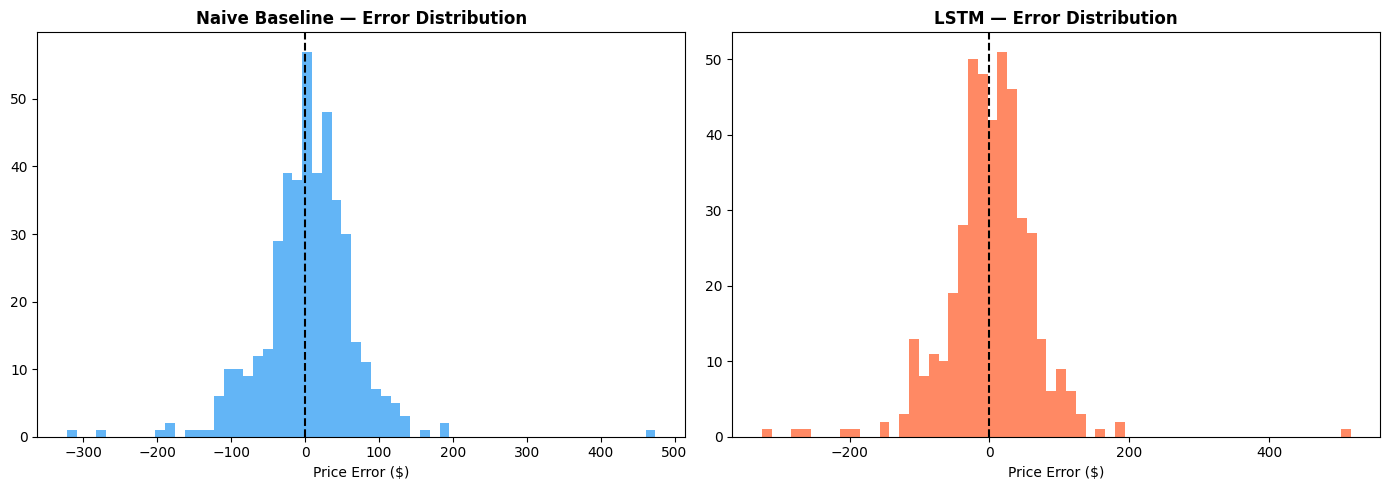

In [33]:
lstm_errors = lstm_metrics["actual_prices"] - lstm_metrics["predicted_prices"]
naive_errors = naive_metrics["actual_prices"] - naive_metrics["predicted_prices"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(naive_errors, bins=60, color="#2196F3", alpha=0.7, edgecolor="none")
axes[0].axvline(0, color="black", linestyle="--")
axes[0].set_title("Naive Baseline \u2014 Error Distribution", fontweight="bold")
axes[0].set_xlabel("Price Error ($)")

axes[1].hist(lstm_errors, bins=60, color="#FF5722", alpha=0.7, edgecolor="none")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("LSTM \u2014 Error Distribution", fontweight="bold")
axes[1].set_xlabel("Price Error ($)")

plt.tight_layout()
plt.show()


  📅  FOLD-LEVEL METRICS  (Monthly Breakdown — Test Set)
   Fold  Days  LSTM RMSE  LSTM MAE  LSTM Dir%  Naive RMSE  Naive MAE
2025-01    20      53.20     44.22       50.0       52.90      44.46
2025-02    19      54.53     41.42       47.4       53.51      41.08
2025-03    21      71.91     58.05       47.6       70.77      58.27
2025-04    21     165.58    104.47       52.4      158.74     106.41
2025-05    21      62.10     42.09       57.1       60.72      42.28
2025-06    20      38.78     32.13       45.0       39.12      31.96
2025-07    22      33.76     24.52       59.1       33.59      24.70
2025-08    21      41.65     33.46       52.4       42.42      33.61
2025-09    21      28.46     25.39       61.9       29.47      26.24
2025-10    23      56.86     39.70       56.5       56.64      39.49
2025-11    19      64.01     52.67       57.9       64.07      53.70
2025-12    22      35.55     28.15       59.1       36.39      28.99
2026-01    20      44.51     31.70       60.0 

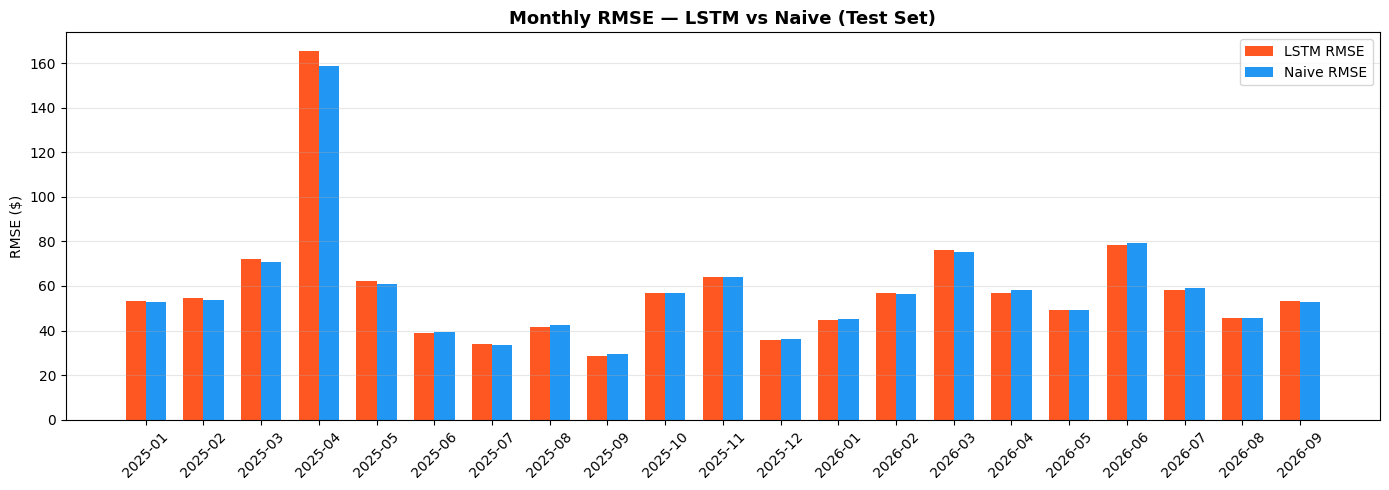

In [34]:
test_dates_series = pd.Series(pd.to_datetime(test_dates))
test_actual_prices = lstm_metrics["actual_prices"]
test_lstm_prices   = lstm_metrics["predicted_prices"]
test_naive_prices  = naive_metrics["predicted_prices"]
test_actual_rets   = all_returns[idx_test]
test_lstm_rets     = lstm_pred_returns

fold_records = []
for (year, month), grp_idx in test_dates_series.groupby(
        [test_dates_series.dt.year, test_dates_series.dt.month]).groups.items():
    idx = grp_idx.values
    fold_label = f"{year}-{month:02d}"

    # LSTM
    lstm_rmse = np.sqrt(mean_squared_error(test_actual_prices[idx], test_lstm_prices[idx]))
    lstm_mae  = mean_absolute_error(test_actual_prices[idx], test_lstm_prices[idx])
    lstm_dir  = accuracy_score(
        (test_actual_rets[idx] > 0).astype(int),
        (test_lstm_rets[idx] > 0).astype(int)
    ) * 100

    # Naive
    naive_rmse = np.sqrt(mean_squared_error(test_actual_prices[idx], test_naive_prices[idx]))
    naive_mae  = mean_absolute_error(test_actual_prices[idx], test_naive_prices[idx])

    fold_records.append({
        "Fold": fold_label,
        "Days": len(idx),
        "LSTM RMSE": round(lstm_rmse, 2),
        "LSTM MAE":  round(lstm_mae, 2),
        "LSTM Dir%": round(lstm_dir, 1),
        "Naive RMSE": round(naive_rmse, 2),
        "Naive MAE":  round(naive_mae, 2),
    })

fold_df = pd.DataFrame(fold_records)
print("\n" + "=" * 85)
print("  \U0001f4c5  FOLD-LEVEL METRICS  (Monthly Breakdown \u2014 Test Set)")
print("=" * 85)
print(fold_df.to_string(index=False))
print("=" * 85)

# Plot fold-level RMSE comparison
fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(fold_df))
w = 0.35
ax.bar(x - w/2, fold_df["LSTM RMSE"], w, label="LSTM RMSE", color="#FF5722")
ax.bar(x + w/2, fold_df["Naive RMSE"], w, label="Naive RMSE", color="#2196F3")
ax.set_xticks(x)
ax.set_xticklabels(fold_df["Fold"], rotation=45)
ax.set_ylabel("RMSE ($)")
ax.set_title("Monthly RMSE \u2014 LSTM vs Naive (Test Set)", fontsize=13, fontweight="bold")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


  🔁  WALK-FORWARD VALIDATION  (Expanding Window)
      Train expands quarterly, always validate on next quarter
  Done: 2021-Q1  Train=  253  Test= 61  RMSE=37.30  MAE=28.58  Dir=60.7%
  Done: 2021-Q2  Train=  314  Test= 63  RMSE=30.66  MAE=23.70  Dir=55.6%
  Done: 2021-Q3  Train=  377  Test= 64  RMSE=32.00  MAE=24.27  Dir=54.7%
  Done: 2021-Q4  Train=  441  Test= 64  RMSE=40.10  MAE=30.84  Dir=50.0%
  Done: 2022-Q1  Train=  505  Test= 62  RMSE=72.97  MAE=58.38  Dir=45.2%
  Done: 2022-Q2  Train=  567  Test= 62  RMSE=78.71  MAE=59.95  Dir=53.2%
  Done: 2022-Q3  Train=  629  Test= 64  RMSE=61.88  MAE=46.39  Dir=57.8%
  Done: 2022-Q4  Train=  693  Test= 63  RMSE=63.64  MAE=49.77  Dir=46.0%
  Done: 2023-Q1  Train=  756  Test= 62  RMSE=42.58  MAE=34.54  Dir=56.5%
  Done: 2023-Q2  Train=  818  Test= 62  RMSE=31.53  MAE=25.36  Dir=56.5%
  Done: 2023-Q3  Train=  880  Test= 63  RMSE=32.66  MAE=26.02  Dir=44.4%
  Done: 2023-Q4  Train=  943  Test= 63  RMSE=42.94  MAE=34.50  Dir=38.1%
  Done: 202

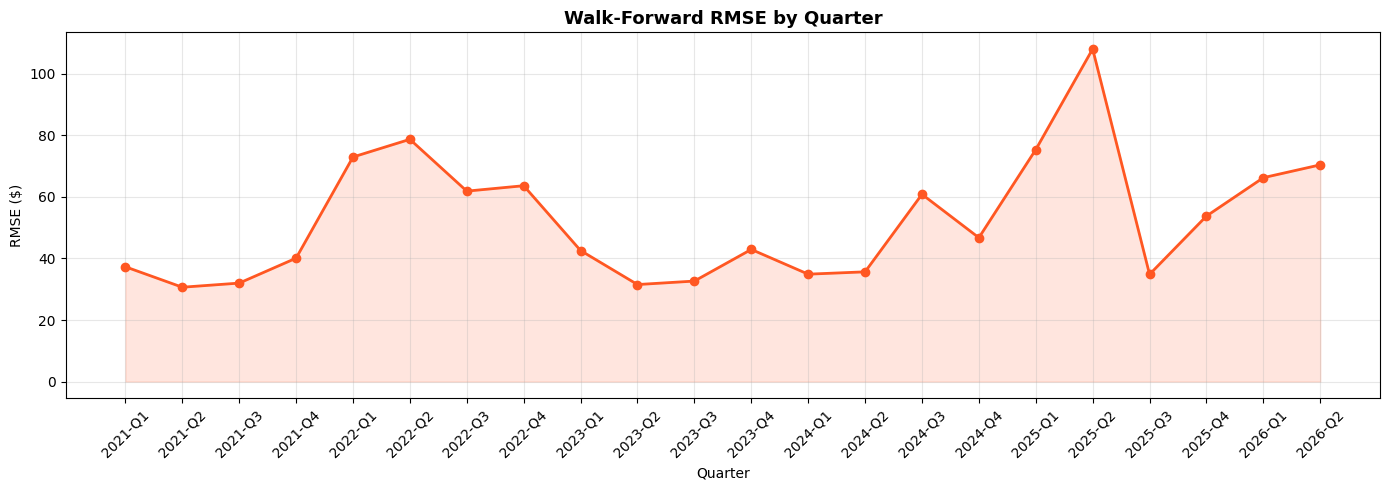

In [35]:
print("\n" + "=" * 70)
print("  \U0001f501  WALK-FORWARD VALIDATION  (Expanding Window)")
print("      Train expands quarterly, always validate on next quarter")
print("=" * 70)

# Define quarterly boundaries within our study window (2020-2026)
quarterly_dates = pd.date_range("2020-01-01", "2026-07-01", freq="QS")

wf_results = []

for i in range(4, len(quarterly_dates) - 1):  # Start with 1 year of training
    train_start = quarterly_dates[0]
    train_end   = quarterly_dates[i] - pd.Timedelta(days=1)
    test_start  = quarterly_dates[i]
    test_end    = quarterly_dates[i + 1] - pd.Timedelta(days=1) if i + 1 < len(quarterly_dates) else pd.Timestamp("2026-12-31")

    # Get data for this fold
    wf_train = df[(df["Date"] >= train_start) & (df["Date"] <= train_end)].copy()
    wf_test  = df[(df["Date"] >= test_start)  & (df["Date"] <= test_end)].copy()

    if len(wf_train) < LOOKBACK + 10 or len(wf_test) < 5:
        continue

    # Fit scaler on this fold's train data
    wf_feat_scaler = StandardScaler()
    wf_tgt_scaler  = StandardScaler()
    wf_feat_scaler.fit(wf_train[FEATURE_COLS].values)
    wf_tgt_scaler.fit(wf_train[["Target_Return"]].values)

    wf_all = pd.concat([wf_train, wf_test], ignore_index=True)
    wf_all[FEATURE_COLS] = wf_feat_scaler.transform(wf_all[FEATURE_COLS].values)
    wf_all["Target_Return_Scaled"] = wf_tgt_scaler.transform(
        wf_all[["Target_Return"]].values
    )

    wf_features = wf_all[FEATURE_COLS].values
    wf_targets  = wf_all["Target_Return_Scaled"].values
    wf_closes   = wf_all["Close"].values
    wf_returns  = wf_all["Target_Return"].values
    wf_trends   = wf_all["Trend"].values

    train_end_i = len(wf_train)
    test_end_i  = len(wf_all)

    X_wf_train, y_wf_train, _ = create_sequences(wf_features, wf_targets, 0, train_end_i)
    X_wf_test,  y_wf_test, wf_idx = create_sequences(wf_features, wf_targets, train_end_i, test_end_i)

    if len(X_wf_test) == 0:
        continue

    # Train a fresh LSTM for this fold
    wf_model = LSTMPredictor(INPUT_SIZE, HIDDEN_SIZE, NUM_LAYERS, DROPOUT).to(DEVICE)
    wf_optim = torch.optim.Adam(wf_model.parameters(), lr=LEARNING_RATE)
    wf_crit  = nn.MSELoss()

    wf_dataset = StockDataset(X_wf_train, y_wf_train)
    wf_loader  = DataLoader(wf_dataset, batch_size=BATCH_SIZE, shuffle=True)

    # Abbreviated training (50 epochs for speed)
    wf_model.train()
    for ep in range(50):
        for xb, yb in wf_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            wf_optim.zero_grad()
            p = wf_model(xb)
            l = wf_crit(p, yb)
            l.backward()
            nn.utils.clip_grad_norm_(wf_model.parameters(), CLIP_NORM)
            wf_optim.step()

    # Predict on this fold's test quarter
    wf_model.eval()
    wf_preds_scaled = []
    wf_test_ds = StockDataset(X_wf_test, y_wf_test)
    wf_test_ld = DataLoader(wf_test_ds, batch_size=BATCH_SIZE, shuffle=False)
    with torch.no_grad():
        for xb, _ in wf_test_ld:
            xb = xb.to(DEVICE)
            wf_preds_scaled.append(wf_model(xb).cpu().numpy())
    wf_preds_scaled = np.concatenate(wf_preds_scaled, axis=0)
    wf_pred_rets = wf_tgt_scaler.inverse_transform(wf_preds_scaled).flatten()

    wf_actual_rets = wf_returns[wf_idx]
    wf_actual_cls  = wf_closes[wf_idx]

    actual_px = wf_actual_cls * (1 + wf_actual_rets)
    pred_px   = wf_actual_cls * (1 + wf_pred_rets)

    rmse_wf = np.sqrt(mean_squared_error(actual_px, pred_px))
    mae_wf  = mean_absolute_error(actual_px, pred_px)
    dir_wf  = accuracy_score(
        (wf_actual_rets > 0).astype(int),
        (wf_pred_rets > 0).astype(int)
    ) * 100

    fold_label = f"{test_start.strftime('%Y-Q')}{(test_start.month-1)//3 + 1}"
    wf_results.append({
        "Fold": fold_label,
        "Train": f"{train_start.date()} -> {train_end.date()}",
        "Test":  f"{test_start.date()} -> {test_end.date()}",
        "Train Size": len(wf_train),
        "Test Size": len(X_wf_test),
        "RMSE": round(rmse_wf, 2),
        "MAE":  round(mae_wf, 2),
        "Dir Acc%": round(dir_wf, 1),
    })
    print(f"  Done: {fold_label}  Train={len(wf_train):>5}  Test={len(X_wf_test):>3}"
          f"  RMSE={rmse_wf:.2f}  MAE={mae_wf:.2f}  Dir={dir_wf:.1f}%")

wf_df = pd.DataFrame(wf_results)
print("\n" + "=" * 90)
print("  Walk-Forward Summary")
print("=" * 90)
print(wf_df.to_string(index=False))
print("=" * 90)
print(f"\n  Average RMSE : {wf_df['RMSE'].mean():.2f}")
print(f"  Average MAE  : {wf_df['MAE'].mean():.2f}")
print(f"  Average Dir% : {wf_df['Dir Acc%'].mean():.1f}%")

# Walk-forward RMSE over time
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(wf_df["Fold"], wf_df["RMSE"], marker="o", linewidth=2, color="#FF5722")
ax.fill_between(range(len(wf_df)), wf_df["RMSE"], alpha=0.15, color="#FF5722")
ax.set_title("Walk-Forward RMSE by Quarter", fontsize=13, fontweight="bold")
ax.set_ylabel("RMSE ($)")
ax.set_xlabel("Quarter")
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:
INITIAL_CAPITAL = 100_000.0

def backtest_strategy(pred_returns, actual_returns, pred_trends, initial_capital=INITIAL_CAPITAL):
    """
    Simple daily backtest:
      BULLISH  -> long  (position = +1)
      BEARISH  -> short (position = -1)
      NEUTRAL  -> flat  (position =  0)
    """
    portfolio = [initial_capital]
    positions = []
    daily_pnl = []

    for i in range(len(actual_returns)):
        trend = pred_trends[i]
        if trend == "BULLISH":
            pos = 1.0
        elif trend == "BEARISH":
            pos = -1.0
        else:
            pos = 0.0

        ret = actual_returns[i]
        pnl = portfolio[-1] * pos * ret
        portfolio.append(portfolio[-1] + pnl)
        positions.append(pos)
        daily_pnl.append(pnl)

    portfolio = np.array(portfolio)
    daily_pnl = np.array(daily_pnl)
    positions = np.array(positions)

    total_return = (portfolio[-1] / initial_capital - 1) * 100
    n_days = len(actual_returns)
    ann_return = ((portfolio[-1] / initial_capital) ** (252 / max(n_days, 1)) - 1) * 100

    daily_rets = np.diff(portfolio) / portfolio[:-1]
    sharpe = np.sqrt(252) * daily_rets.mean() / (daily_rets.std() + 1e-10)

    # Max drawdown
    peak = np.maximum.accumulate(portfolio)
    drawdown = (portfolio - peak) / peak
    max_dd = drawdown.min() * 100

    # Win rate
    wins = (daily_pnl > 0).sum()
    trades = (positions != 0).sum()
    win_rate = (wins / max(trades, 1)) * 100

    return {
        "portfolio": portfolio,
        "positions": positions,
        "daily_pnl": daily_pnl,
        "total_return": total_return,
        "ann_return": ann_return,
        "sharpe": sharpe,
        "max_drawdown": max_dd,
        "win_rate": win_rate,
        "n_trades": int(trades),
    }


# Buy-and-hold benchmark
bh_returns = all_returns[idx_test]
bh_portfolio = [INITIAL_CAPITAL]
for r in bh_returns:
    bh_portfolio.append(bh_portfolio[-1] * (1 + r))
bh_portfolio = np.array(bh_portfolio)
bh_total_return = (bh_portfolio[-1] / INITIAL_CAPITAL - 1) * 100
bh_ann_return = ((bh_portfolio[-1] / INITIAL_CAPITAL) ** (252 / len(bh_returns)) - 1) * 100
bh_daily_rets = np.diff(bh_portfolio) / bh_portfolio[:-1]
bh_sharpe = np.sqrt(252) * bh_daily_rets.mean() / (bh_daily_rets.std() + 1e-10)
bh_peak = np.maximum.accumulate(bh_portfolio)
bh_max_dd = ((bh_portfolio - bh_peak) / bh_peak).min() * 100

# LSTM strategy
lstm_bt = backtest_strategy(
    lstm_pred_returns, all_returns[idx_test],
    lstm_metrics["predicted_trends"]
)

# Naive strategy
naive_bt = backtest_strategy(
    naive_pred_returns_test, all_returns[idx_test],
    naive_metrics["predicted_trends"]
)

# Linear strategy
lin_bt = backtest_strategy(
    lin_pred_returns_test, all_returns[idx_test],
    lin_metrics["predicted_trends"]
)

print("\n" + "=" * 90)
print("  BACKTESTING RESULTS  (Test Set: 2025 -> 2026)")
print("  Strategy: Long if BULLISH, Short if BEARISH, Flat if NEUTRAL")
print("=" * 90)
print(f"\n{'Strategy':<22} {'Total Return':>14} {'Ann. Return':>12} "
      f"{'Sharpe':>8} {'Max DD':>8} {'Win Rate':>9} {'Trades':>7}")
print("-" * 90)
for name, bt in [("Buy & Hold", {"total_return": bh_total_return,
                                  "ann_return": bh_ann_return,
                                  "sharpe": bh_sharpe,
                                  "max_drawdown": bh_max_dd,
                                  "win_rate": "-", "n_trades": len(bh_returns)}),
                 ("Naive Baseline", naive_bt),
                 ("Linear Regression", lin_bt),
                 ("LSTM Strategy", lstm_bt)]:
    wr = bt['win_rate'] if isinstance(bt['win_rate'], str) else f"{bt['win_rate']:.1f}%"
    print(f"  {name:<20} {bt['total_return']:>+12.2f}%  {bt['ann_return']:>+10.2f}%"
          f"  {bt['sharpe']:>+7.3f}  {bt['max_drawdown']:>+7.2f}%  {wr:>8}  {bt['n_trades']:>6}")
print("=" * 90)


  BACKTESTING RESULTS  (Test Set: 2025 -> 2026)
  Strategy: Long if BULLISH, Short if BEARISH, Flat if NEUTRAL

Strategy                 Total Return  Ann. Return   Sharpe   Max DD  Win Rate  Trades
------------------------------------------------------------------------------------------
  Buy & Hold                 +31.95%      +17.51%   +1.054   -18.90%         -     433
  Naive Baseline              +0.00%       +0.00%   +0.000    +0.00%      0.0%       0
  Linear Regression           +1.60%       +0.93%   +0.225    -5.12%     63.3%      30
  LSTM Strategy               -4.28%       -2.51%   -0.261   -12.65%     66.7%       9


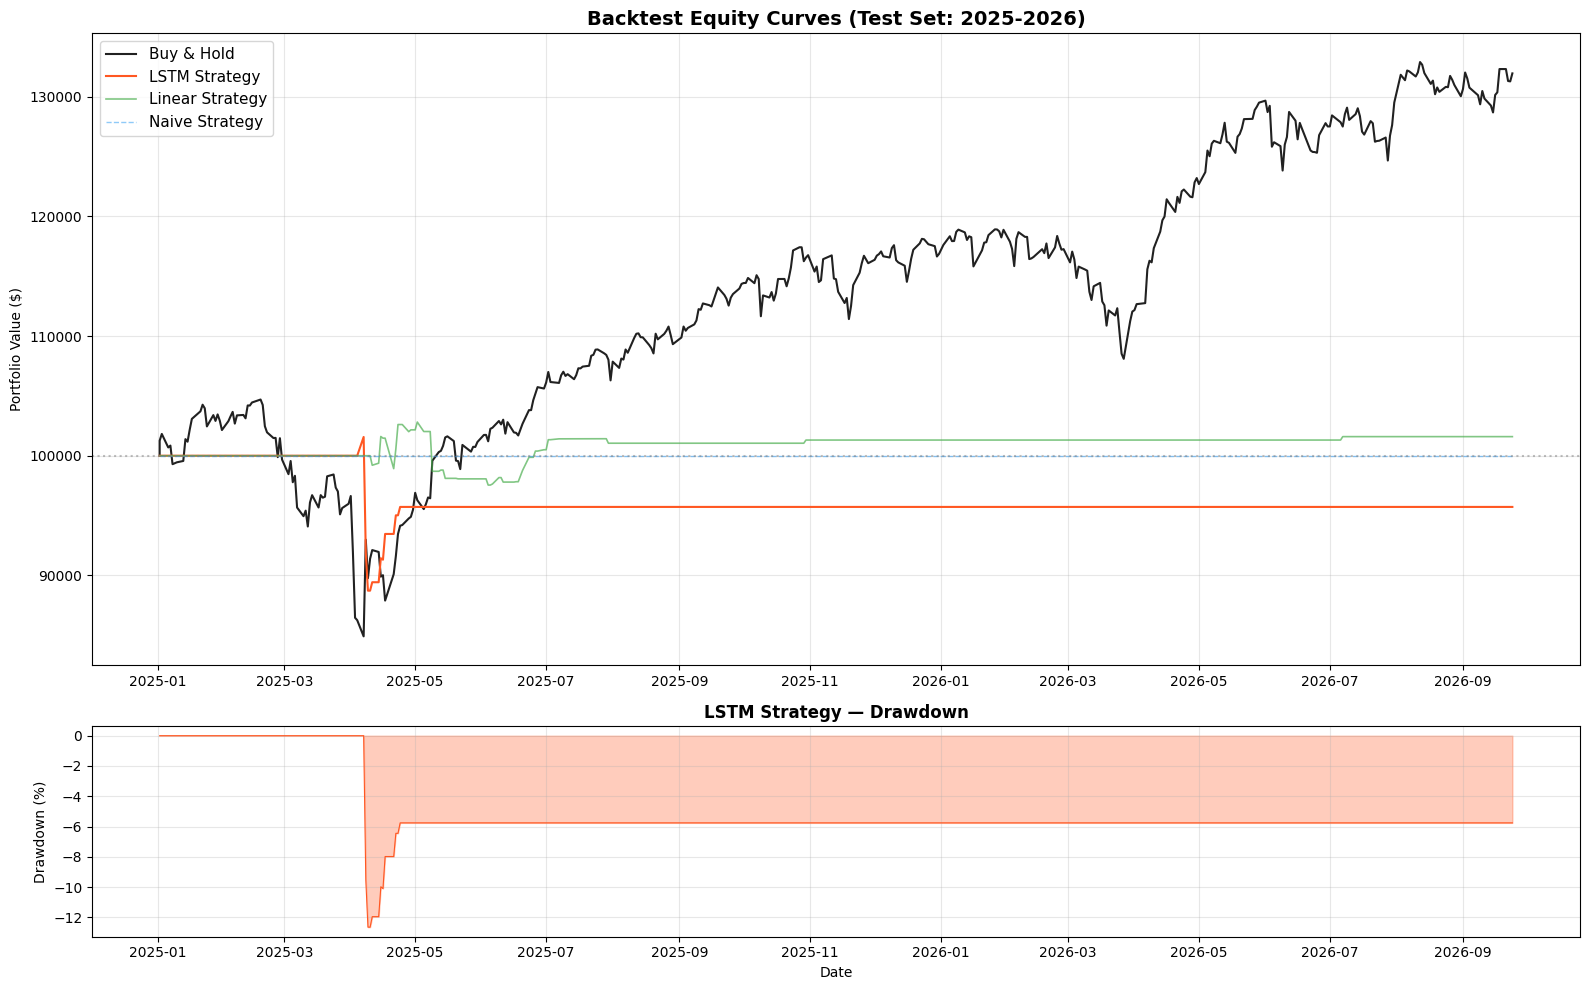

In [37]:
test_dates = all_dates[idx_test]
fig, axes = plt.subplots(2, 1, figsize=(16, 10), gridspec_kw={"height_ratios": [3, 1]})

# Equity curves
test_dates_ext = np.concatenate([[test_dates[0]], test_dates])  # +1 for initial capital

axes[0].plot(test_dates_ext, bh_portfolio, label="Buy & Hold",
             linewidth=1.5, color="#212121")
axes[0].plot(test_dates_ext, lstm_bt["portfolio"], label="LSTM Strategy",
             linewidth=1.5, color="#FF5722")
axes[0].plot(test_dates_ext, lin_bt["portfolio"], label="Linear Strategy",
             linewidth=1.2, color="#4CAF50", alpha=0.7)
axes[0].plot(test_dates_ext, naive_bt["portfolio"], label="Naive Strategy",
             linewidth=1, color="#2196F3", alpha=0.5, linestyle="--")
axes[0].axhline(INITIAL_CAPITAL, color="gray", linestyle=":", alpha=0.5)
axes[0].set_title("Backtest Equity Curves (Test Set: 2025-2026)",
                   fontsize=14, fontweight="bold")
axes[0].set_ylabel("Portfolio Value ($)")
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.3)

# Drawdown
peak = np.maximum.accumulate(lstm_bt["portfolio"])
dd = (lstm_bt["portfolio"] - peak) / peak * 100
axes[1].fill_between(test_dates_ext, dd, color="#FF5722", alpha=0.3)
axes[1].plot(test_dates_ext, dd, color="#FF5722", linewidth=0.8)
axes[1].set_title("LSTM Strategy \u2014 Drawdown", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Drawdown (%)")
axes[1].set_xlabel("Date")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

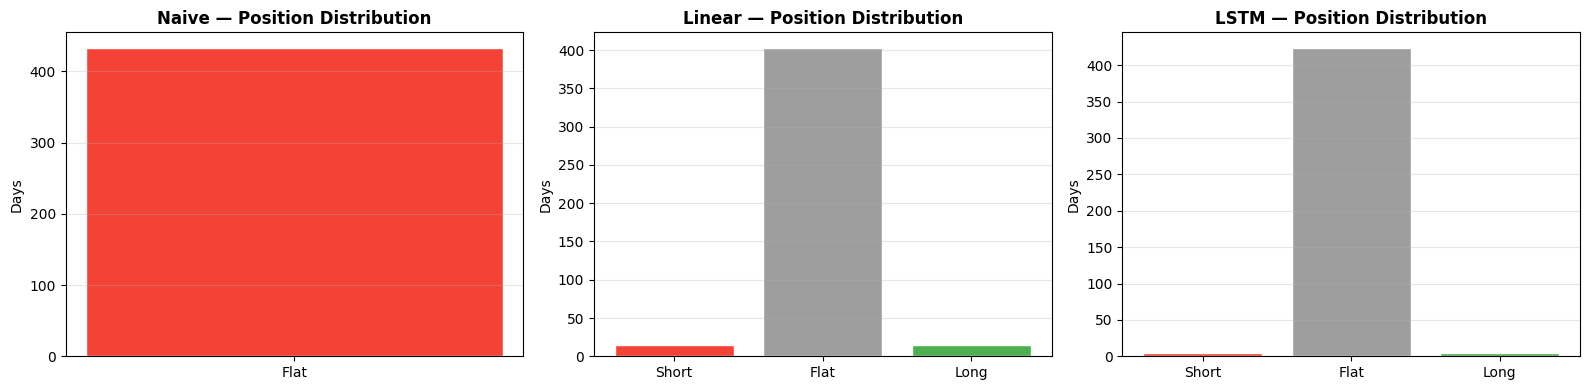

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, bt) in zip(axes, [("Naive", naive_bt), ("Linear", lin_bt), ("LSTM", lstm_bt)]):
    pos_counts = pd.Series(bt["positions"]).value_counts().sort_index()
    pos_labels = {-1: "Short", 0: "Flat", 1: "Long"}
    ax.bar([pos_labels.get(k, k) for k in pos_counts.index], pos_counts.values,
           color=["#F44336", "#9E9E9E", "#4CAF50"], edgecolor="white")
    ax.set_title(f"{name} \u2014 Position Distribution", fontweight="bold")
    ax.set_ylabel("Days")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()